# Lab 10 — Image Segmentation and Feature Extraction
**Course:** ARTI404 – Image Processing  
**College of Computer Science and Information Technology**  
**Imam Abdulrahman Bin Faisal University**

This notebook uses the **provided fox photograph** as the common input image for the lab demonstrations:
1. Canny Edge Detection.
2. Harris Corner Detection.
3. Simple (global) binary thresholding.
4. Otsu's automatic thresholding (assessment task).
5. Optional GrabCut foreground extraction to demonstrate a more suitable object-segmentation method for a natural photograph.

**Important:** Keep `images.jpg` in the same folder as this notebook. The ZIP package supplied with this notebook already contains both files.

## Setup — Import libraries and load the fox image

The image is read once in this cell and reused in every task. OpenCV loads it in BGR format, so we also create an RGB copy for correct display with Matplotlib and a grayscale copy for the algorithms.

Loaded image: images.jpg
Image dimensions: 495 x 619 pixels


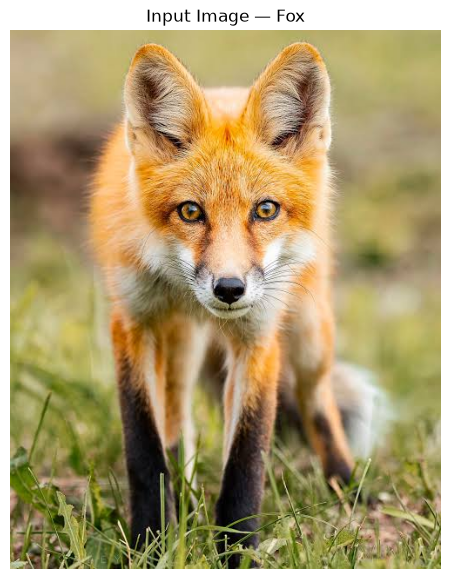

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Locate the image file. Keep images.jpg beside this notebook (or inside a data folder).
image_candidates = [Path("images.jpg"), Path("data") / "images.jpg"]
image_path = next((p for p in image_candidates if p.is_file()), None)

if image_path is None:
    raise FileNotFoundError(
        "Could not find images.jpg. Keep the supplied fox photo in the same folder "
        "as this notebook, then run this cell again."
    )

# Load and prepare the image
img_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
if img_bgr is None:
    raise ValueError(f"OpenCV could not read the image: {image_path}")

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# A lightly blurred grayscale image reduces small noise before edge/corner detection.
gray_blur = cv2.GaussianBlur(gray, (5, 5), 0)

print(f"Loaded image: {image_path}")
print(f"Image dimensions: {img_rgb.shape[1]} x {img_rgb.shape[0]} pixels")

plt.figure(figsize=(6, 7))
plt.imshow(img_rgb)
plt.title("Input Image — Fox")
plt.axis("off")
plt.show()

## Task 1 — Canny Edge Detection

An **edge** is where brightness changes sharply. Canny (1986) finds edges in 5 steps: Gaussian blur → gradients → non-maximum suppression (thin the edges) → double thresholding → hysteresis (keep weak edges only if they connect to strong ones).

`cv2.Canny(img, T_low, T_high)`:
- `T_low` = lower threshold (weak edges)
- `T_high` = upper threshold (strong edges)
- Rule of thumb: `T_high ≈ 2×T_low` or `3×T_low`.

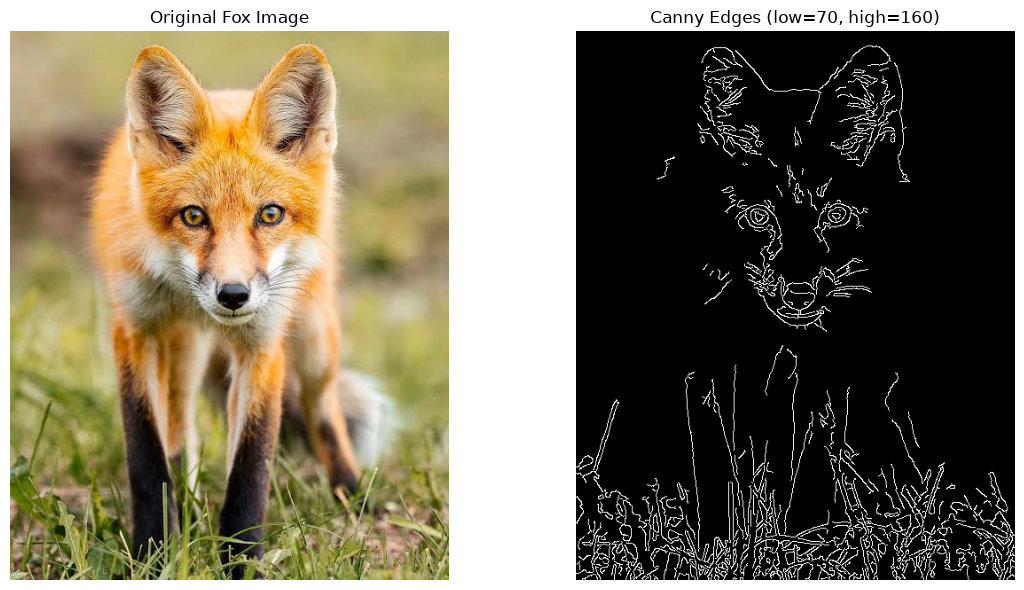

Detected edge pixels: 16,083


In [2]:
# --- Task 1: Canny Edge Detection on the fox photo ---
# Blur slightly to reduce noise, then detect edges.
T_low = 70
T_high = 160
edges = cv2.Canny(gray_blur, T_low, T_high)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Fox Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap="gray")
plt.title(f"Canny Edges (low={T_low}, high={T_high})")
plt.axis("off")

plt.tight_layout()
plt.show()
print(f"Detected edge pixels: {np.count_nonzero(edges):,}")

## Task 2 — Harris Corner Detection

A **corner** is a point where the image changes in *two* different directions — which makes corners highly distinctive (useful for matching, tracking, camera calibration).



- Large positive `R` → corner
- Large negative `R` → edge
- Small `R` → flat region

Parameters: `blockSize` (window size), `ksize` (Sobel kernel size), `k` (sensitivity, typically 0.04–0.06).

> **Note:** OpenCV uses BGR order, so `(0, 0, 255)` is red.

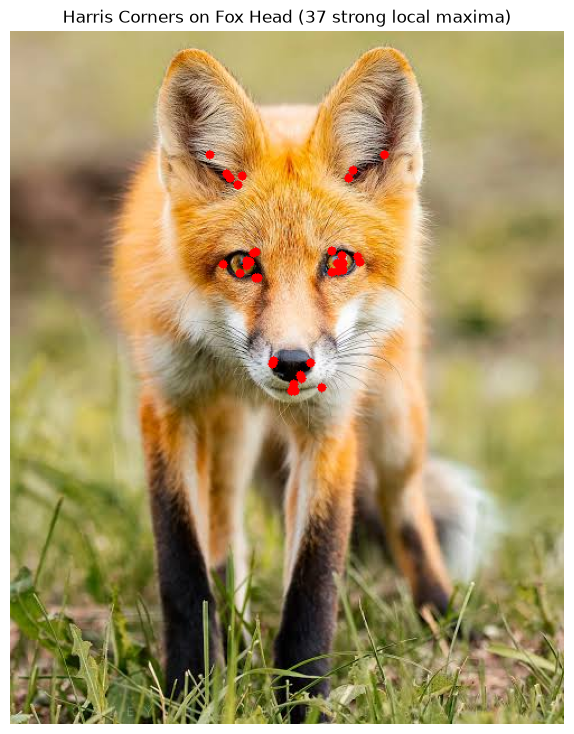

Number of marked Harris corners inside the head region: 37


In [3]:
# --- Task 2: Harris Corner Detection on the fox photo ---
# Harris expects a single-channel float32 image.
gray_float = np.float32(gray_blur)
harris_response = cv2.cornerHarris(gray_float, blockSize=2, ksize=3, k=0.04)

# Focus the visualization on the fox's head. Without this display mask, the
# detailed grass also creates many strong corners and distracts from the subject.
head_roi = np.zeros(gray.shape, dtype=np.uint8)
cv2.ellipse(head_roi, center=(247, 220), axes=(135, 145), angle=0,
            startAngle=0, endAngle=360, color=255, thickness=-1)

# Dilate the response and keep only strong local maxima inside the head ROI.
harris_dilated = cv2.dilate(harris_response, None)
head_max_response = harris_response[head_roi > 0].max()
corner_threshold = 0.15 * head_max_response
corner_mask = (
    np.isclose(harris_response, harris_dilated, rtol=1e-5, atol=1e-8)
    & (harris_response > corner_threshold)
    & (head_roi > 0)
)
corner_coords = np.argwhere(corner_mask)

# Draw red circles on a copy of the original RGB image.
corner_result = img_rgb.copy()
for y, x in corner_coords:
    cv2.circle(corner_result, (int(x), int(y)), radius=4, color=(255, 0, 0), thickness=-1)

plt.figure(figsize=(8, 9))
plt.imshow(corner_result)
plt.title(f"Harris Corners on Fox Head ({len(corner_coords)} strong local maxima)")
plt.axis("off")
plt.show()
print(f"Number of marked Harris corners inside the head region: {len(corner_coords)}")

## Simple (Global) Binary Thresholding
The most basic segmentation: pick a fixed threshold `T` and turn every pixel above it white, below it black.

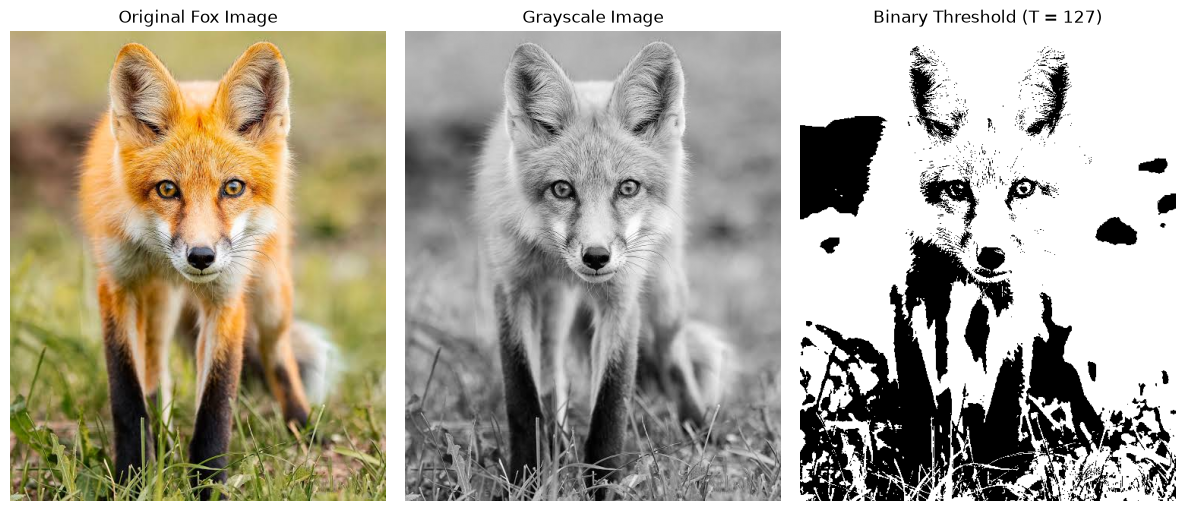

In [4]:
# --- Simple (Global) Binary Thresholding on the fox photo ---
# This uses the fixed threshold from the lab example.
T = 127
_, binary = cv2.threshold(gray, T, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title("Original Fox Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(binary, cmap="gray")
plt.title(f"Binary Threshold (T = {T})")
plt.axis("off")

plt.tight_layout()
plt.show()

## Q1 — Otsu's Thresholding (Assessment Task)
Otsu picks `T` **automatically** by maximizing the between-class variance — assumes the histogram has two peaks (foreground + background).

show the original image, its histogram, and the thresholded image.

### Solution — Otsu's automatic thresholding

Otsu's method calculates a threshold from the grayscale histogram instead of requiring a manually selected value. In OpenCV, combine `cv2.THRESH_BINARY` with `cv2.THRESH_OTSU` and pass `0` as the initial threshold.

The code displays the original fox photograph, its 256-bin grayscale histogram (with the automatically selected threshold marked), and the binary result. **Note:** Otsu creates a global intensity-based mask; it does not guarantee a clean object outline when the subject and background have overlapping brightness values.

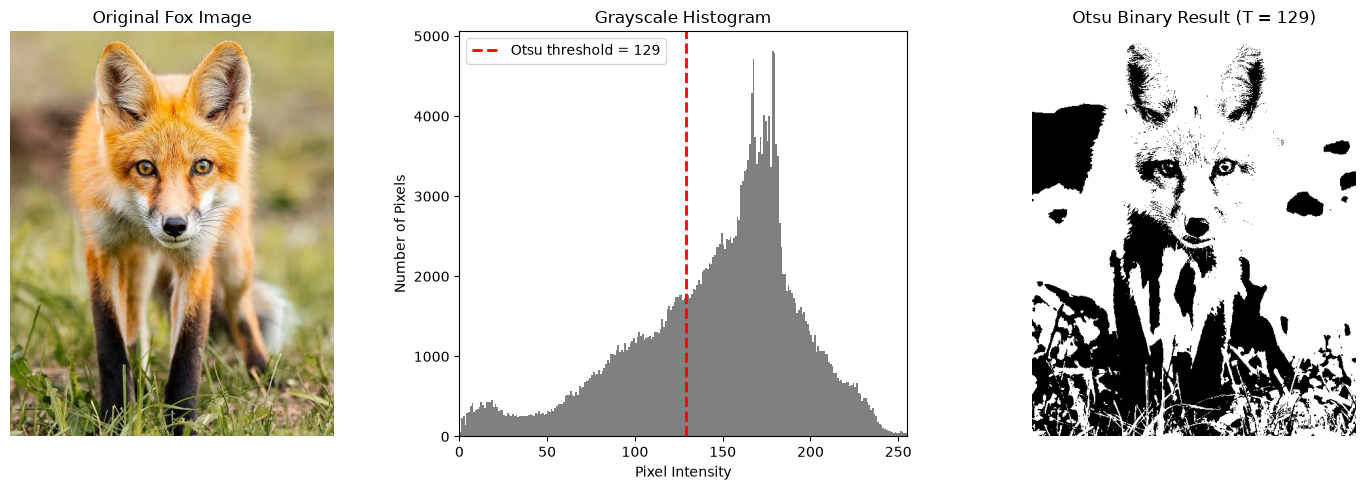

Automatically selected Otsu threshold: 129
White pixels in Otsu mask: 68.7%


In [5]:
# --- Q1: Otsu's automatic thresholding on the fox photo ---
# Otsu automatically calculates the best global grayscale threshold.
otsu_threshold, otsu_binary = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Display the original image, grayscale histogram, and binary result.
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title("Original Fox Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.hist(gray.ravel(), bins=256, range=(0, 256), color="gray")
plt.axvline(
    otsu_threshold,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Otsu threshold = {otsu_threshold:.0f}"
)
plt.title("Grayscale Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Number of Pixels")
plt.xlim(0, 255)
plt.legend()

plt.subplot(1, 3, 3)
plt.imshow(otsu_binary, cmap="gray")
plt.title(f"Otsu Binary Result (T = {otsu_threshold:.0f})")
plt.axis("off")

plt.tight_layout()
plt.show()

white_percent = 100 * np.count_nonzero(otsu_binary == 255) / otsu_binary.size
print(f"Automatically selected Otsu threshold: {otsu_threshold:.0f}")
print(f"White pixels in Otsu mask: {white_percent:.1f}%")

---
## Optional — Foreground Extraction with GrabCut

Otsu is useful for the assessment because it demonstrates automatic global thresholding, but a natural photo often has foreground and background pixels with similar brightness. GrabCut is an additional OpenCV method that uses color models and a rough foreground outline to separate the subject.

The initial outline and seed regions below are tailored to this supplied fox photograph. The output is an assisted segmentation result, so inspect the mask; a few grass pixels may remain near the feet because the fox is standing in grass.

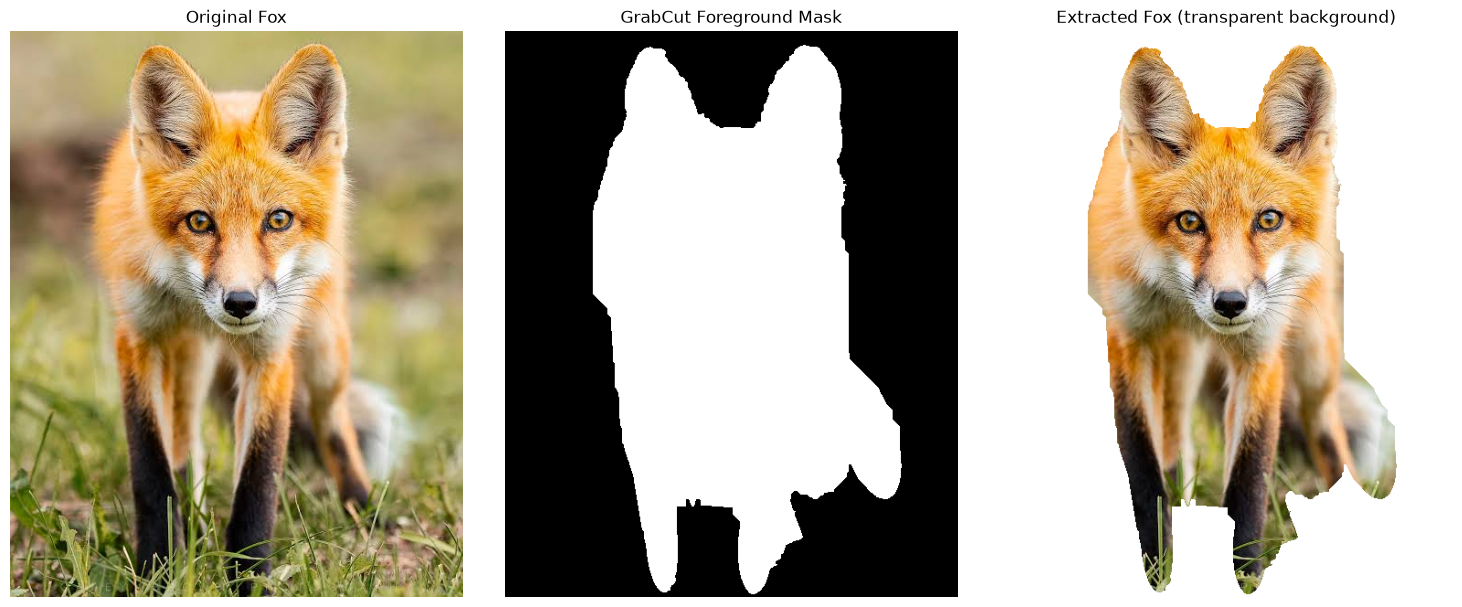

GrabCut foreground area: 42.9% of the image
Saved: fox_grabcut_mask.png and fox_segmented_transparent.png


In [6]:
# --- Optional: GrabCut foreground extraction on this fox photo ---
height, width = gray.shape

# The reference outline is defined for the supplied 495x619 photo.
# Scale the coordinates automatically if the photo is resized.
scale_x = width / 495.0
scale_y = height / 619.0

def scale_points(points):
    return np.array(
        [[round(x * scale_x), round(y * scale_y)] for x, y in points],
        dtype=np.int32
    )

# Rough polygon around the fox, including its ears, body, legs, and visible tail.
fox_outline = scale_points([
    (135, 28), (150, 12), (179, 15), (195, 45), (211, 92),
    (230, 82), (254, 82), (276, 66), (296, 26), (319, 12),
    (343, 18), (362, 42), (374, 90), (370, 140), (389, 180),
    (399, 245), (397, 310), (385, 350), (405, 377), (430, 415),
    (441, 456), (432, 488), (408, 511), (390, 497), (377, 470),
    (366, 520), (350, 575), (334, 615), (305, 615), (287, 582),
    (278, 548), (265, 528), (245, 550), (224, 590), (205, 615),
    (175, 615), (160, 585), (150, 545), (140, 485), (125, 440),
    (108, 397), (95, 350), (89, 290), (90, 235), (98, 187),
    (110, 150), (120, 105)
])

# GrabCut labels: definite background by default, probable foreground inside outline.
gc_mask = np.zeros((height, width), dtype=np.uint8)
cv2.fillPoly(gc_mask, [fox_outline], cv2.GC_PR_FGD)

# Mark known background areas inside the broad outline: the gap between the legs
# and the background visible between the ears.
def scaled_rect(x1, y1, x2, y2):
    return (round(x1 * scale_x), round(y1 * scale_y),
            round(x2 * scale_x), round(y2 * scale_y))

x1, y1, x2, y2 = scaled_rect(188, 520, 248, 618)
cv2.rectangle(gc_mask, (x1, y1), (x2, y2), cv2.GC_BGD, thickness=-1)
cv2.fillPoly(
    gc_mask,
    [scale_points([(218, 72), (240, 60), (266, 60), (284, 72), (271, 105), (235, 105)])],
    cv2.GC_BGD
)

# Sure-foreground seeds in the ears, face/body, legs, and visible tail.
def scaled_center(center):
    return (round(center[0] * scale_x), round(center[1] * scale_y))

def scaled_axes(axes):
    return (max(1, round(axes[0] * scale_x)), max(1, round(axes[1] * scale_y)))

foreground_seeds = [
    ((170, 77), (24, 55), -10),
    ((329, 75), (27, 56), 10),
    ((248, 225), (100, 120), 0),
    ((245, 400), (72, 120), 0),
    ((171, 558), (17, 55), -3),
    ((274, 560), (19, 55), 3),
    ((400, 443), (28, 70), -15),
]
for center, axes, angle in foreground_seeds:
    cv2.ellipse(
        gc_mask,
        scaled_center(center),
        scaled_axes(axes),
        angle,
        0,
        360,
        cv2.GC_FGD,
        thickness=-1
    )

background_model = np.zeros((1, 65), dtype=np.float64)
foreground_model = np.zeros((1, 65), dtype=np.float64)
cv2.grabCut(
    img_bgr,
    gc_mask,
    None,
    background_model,
    foreground_model,
    10,
    cv2.GC_INIT_WITH_MASK
)

# Convert GrabCut labels into a clean 0/255 foreground mask.
fox_mask = np.where(
    (gc_mask == cv2.GC_FGD) | (gc_mask == cv2.GC_PR_FGD),
    255,
    0
).astype(np.uint8)

# Mild closing joins tiny gaps without heavily changing the outline.
fox_mask = cv2.morphologyEx(
    fox_mask,
    cv2.MORPH_CLOSE,
    np.ones((3, 3), dtype=np.uint8)
)

# Create a transparent PNG of the extracted foreground.
fox_rgba = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGBA)
fox_rgba[:, :, 3] = fox_mask

fig, axes = plt.subplots(1, 3, figsize=(15, 6))
axes[0].imshow(img_rgb)
axes[0].set_title("Original Fox")
axes[0].axis("off")

axes[1].imshow(fox_mask, cmap="gray")
axes[1].set_title("GrabCut Foreground Mask")
axes[1].axis("off")

axes[2].imshow(fox_rgba)
axes[2].set_title("Extracted Fox (transparent background)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

# Save the mask and transparent extraction next to the notebook.
cv2.imwrite("fox_grabcut_mask.png", fox_mask)
cv2.imwrite("fox_segmented_transparent.png", cv2.cvtColor(fox_rgba, cv2.COLOR_RGBA2BGRA))
print(f"GrabCut foreground area: {100 * np.mean(fox_mask > 0):.1f}% of the image")
print("Saved: fox_grabcut_mask.png and fox_segmented_transparent.png")

---
## Summary table

| Technique | Category | What it finds | OpenCV function |
|---|---|---|---|
| Canny | Edge detection | Thin connected edges | `cv2.Canny` |
| Sobel | Edge detection | Gradient magnitude (thick) | `cv2.Sobel` |
| Laplacian | Edge detection | Zero-crossings (2nd deriv) | `cv2.Laplacian` |
| Harris | Feature extraction | Corners | `cv2.cornerHarris` |
| Shi-Tomasi | Feature extraction | Corners (improved) | `cv2.goodFeaturesToTrack` |
| Simple threshold | Segmentation | Fixed-`T` binary mask | `cv2.threshold` |
| Otsu | Segmentation | Auto global intensity threshold | `cv2.threshold` + `THRESH_OTSU` |
| GrabCut (optional) | Foreground segmentation | Subject mask using color models and initialization | `cv2.grabCut` |
| Adaptive threshold | Segmentation | Local-`T` binary mask | `cv2.adaptiveThreshold` |

**End of notebook.**